# HW1 Part E - Sensitivity Analysis

Running the SEIR model from Part D for many values of beta and gamma, and looking at how the peak and the total number of infections change.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

In [14]:
def seir_model(S0, E0, I0, R0, N, beta, gamma, sigma, mu, days, dt=0.1):
    n = int(days / dt)

    t = np.zeros(n + 1)
    S = np.zeros(n + 1)
    E = np.zeros(n + 1)
    I = np.zeros(n + 1)
    R = np.zeros(n + 1)
    new_inf = 0  # total new infections

    S[0] = S0
    E[0] = E0
    I[0] = I0
    R[0] = R0

    for k in range(n):
        dS = mu * N - beta * S[k] * I[k] - mu * S[k]
        dE = beta * S[k] * I[k] - (sigma + mu) * E[k]
        dI = sigma * E[k] - (gamma + mu) * I[k]
        dR = gamma * I[k] - mu * R[k]

        S[k + 1] = S[k] + dt * dS
        E[k + 1] = E[k] + dt * dE
        I[k + 1] = I[k] + dt * dI
        R[k + 1] = R[k] + dt * dR
        t[k + 1] = t[k] + dt

        # people moving from S to E in this step are new infections
        new_inf = new_inf + dt * beta * S[k] * I[k]

    return t, S, E, I, R, new_inf

## i. Grid of beta and gamma values

Using 9 values for each.

In [15]:
N = 2000
sigma = 0.25
mu = 0.005

betas = np.linspace(0.05e-3, 0.25e-3, 9)
gammas = np.linspace(0.05, 0.25, 9)

print('beta values:', betas)
print('gamma values:', gammas)

beta values: [5.00e-05 7.50e-05 1.00e-04 1.25e-04 1.50e-04 1.75e-04 2.00e-04 2.25e-04
 2.50e-04]
gamma values: [0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]


In [16]:
peak = np.zeros((len(betas), len(gammas)))
total = np.zeros((len(betas), len(gammas)))
R0_grid = np.zeros((len(betas), len(gammas)))

for i in range(len(betas)):
    for j in range(len(gammas)):
        b = betas[i]
        g = gammas[j]
        t, S, E, I, R, new_inf = seir_model(1980, 15, 5, 0, N, b, g, sigma, mu, 365)
        peak[i, j] = np.max(I)
        total[i, j] = new_inf
        R0_grid[i, j] = b * N * sigma / ((sigma + mu) * (g + mu))

## ii. Results

Tables first (rows = beta, columns = gamma).

In [17]:
print('Peak infected (rows = beta x 1e-3, columns = gamma)')
print('gamma:      ', np.round(gammas, 3))
for i in range(len(betas)):
    print(round(betas[i] * 1000, 3), '  ', np.round(peak[i]).astype(int))

print()
print('Total new infections in 365 days')
print('gamma:      ', np.round(gammas, 3))
for i in range(len(betas)):
    print(round(betas[i] * 1000, 3), '  ', np.round(total[i]).astype(int))

Peak infected (rows = beta x 1e-3, columns = gamma)
gamma:       [0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]
0.05    [231  47  13  12  11  10   9   9   8]
0.075    [468 220  85  22  12  10  10   9   8]
0.1    [634 374 208 104  43  15  10   9   9]
0.125    [753 494 318 196 113  59  27  12   9]
0.15    [841 588 409 279 185 117  70  38  19]
0.175    [908 663 484 351 251 175 118  77  47]
0.2    [962 723 547 413 309 228 166 118  81]
0.225    [1005  773  599  465  360  276  210  158  116]
0.25    [1040  815  644  511  405  320  251  195  150]

Total new infections in 365 days
gamma:       [0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]
0.05    [2281 1050  172   57   33   23   18   15   12]
0.075    [3199 2299 1568  755  196   79   48   34   26]
0.1    [3859 3097 2319 1739 1199  604  209   97   61]
0.125    [4195 3682 3074 2378 1839 1411  975  515  217]
0.15    [4406 3970 3559 3072 2462 1931 1540 1192  826]
0.175    [4565 4163 3800 3464 3069 2551 2031 1643 1333]
0.2    [46

For the R0 = 1 line I solved the R0 formula for beta:

R0 = beta * N * sigma / ((sigma + mu)(gamma + mu)) = 1  ->  beta = (sigma + mu)(gamma + mu) / (N * sigma)

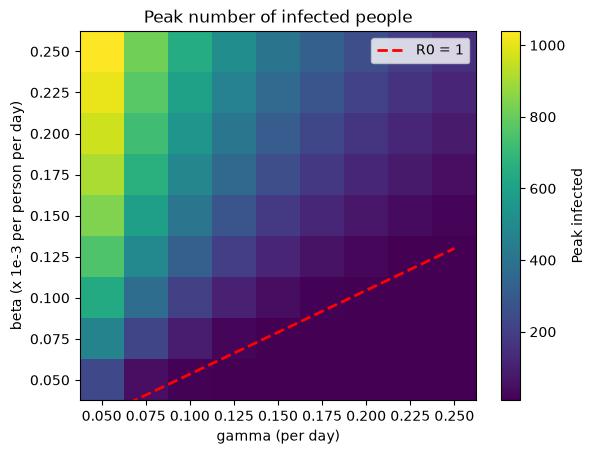

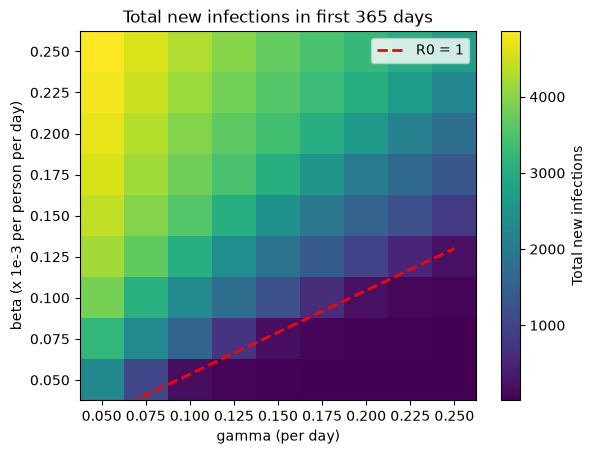

In [19]:
# R0 = 1 line
g_line = np.linspace(0.05, 0.25, 100)
b_line = (sigma + mu) * (g_line + mu) / (N * sigma)

# peak infected
plt.pcolormesh(gammas, betas * 1000, peak, cmap='viridis', shading='nearest')
plt.colorbar(label='Peak infected')
plt.plot(g_line, b_line * 1000, 'r--', linewidth=2, label='R0 = 1')
plt.ylim(0.0375, 0.2625)
plt.xlabel('gamma (per day)')
plt.ylabel('beta (x 1e-3 per person per day)')
plt.title('Peak number of infected people')
plt.legend()
plt.show()

# total new infections
plt.pcolormesh(gammas, betas * 1000, total, cmap='viridis', shading='nearest')
plt.colorbar(label='Total new infections')
plt.plot(g_line, b_line * 1000, 'r--', linewidth=2, label='R0 = 1')
plt.ylim(0.0375, 0.2625)
plt.xlabel('gamma (per day)')
plt.ylabel('beta (x 1e-3 per person per day)')
plt.title('Total new infections in first 365 days')
plt.legend()
plt.show()

**How to read the heatmaps:**
- Each square is one simulation with one beta and one gamma.
- Yellow = a lot of infections, dark purple = very few.
- Going up (vertically) means higher beta. Going right (horizontally) means higher gamma.
- The red dashed line is R0 = 1. Above the line there is an outbreak. Below the line there is no outbreak.

- high beta, low gamma: peak over 1040 infected, more than 4800 new infections in a year.
- low beta, high gamma: peak about 8, only about 12 new infections.
- beta = 0.125e-3, gamma = 0.1: peak about 318, about 3070 new infections.
- The further above the red line, the bigger the outbreak. Right next to the line the outbreak is very small.
- Both plots look almost the same



**My hypothesis was that beta would affect the peak more than gamma.**

What the results showed, starting from the Part D values (peak about 318):
- beta 2.5 times smaller (0.125e-3 -> 0.05e-3): peak drops to about 13
- gamma 2.5 times bigger (0.1 -> 0.25): peak drops to about 9

Both seem have a big and almost equal effect, but gamma is actually stronger. My hypothesis proved not to be right. I think the reason is that a higher gamma also means people are sick for a shorter time, so fewer people are sick at the same moment.

## iii. Public health implications

**beta = social distancing.** Beta is how easily the disease spreads between people. Social distancing, masks, staying home when sick and limiting big gatherings all lower beta. In the plots, lowering beta means moving down. From the Part D values, cutting beta by more than half (to below about 0.054e-3) pushes R0 below 1 and stops the outbreak.

**gamma = medical treatment.** Gamma is how fast infected people stop being infectious. Better treatment, faster testing and isolating sick people (so they stop spreading sooner) increase gamma in practice. In the plots, raising gamma means moving right. From the Part D values, raising gamma above about 0.24 brings R0 below 1.